# Prova de **Análise de Dados**

In [ ]:
# Importando bibliotecas
import pandas as pd
from sklearn.tree import DecisionTreeClassifier #Decision Tree Classifier
from sklearn import metrics #Import scikit-learn metrics module for accuracy calculation

In [ ]:
#Avaliação
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve

def metricas(y_pred):
  print(classification_report(y_val, y_pred))
  print('Matriz de confusão:','\n' , confusion_matrix(y_val, y_pred))

In [ ]:
#Baixando os dados de treino e teste
train_data = pd.read_csv('/content/treino.csv')
test_data = pd.read_csv('/content/teste.csv')

<class 'pandas.core.frame.DataFrame'>


In [ ]:
#Dividindo o conjunto de treino em inputs e labels
x_train_full = train_data.drop(['id', 'target'], axis=1)
y_train_full = train_data['target']

In [ ]:
from sklearn.model_selection import train_test_split
#Dividindo o conjunto de treino em treino e validação
x_train, x_val, y_train, y_val = train_test_split(x_train_full, y_train_full, test_size=0.1, random_state=42)

In [ ]:
from sklearn.model_selection import train_test_split

for split in [0.1, 0.2, 0.3]:  # Testando 90/10, 80/20 e 70/30
    x_train, x_val, y_train, y_val = train_test_split(x_train_full, y_train_full, test_size=0.1, random_state=42)

    clf.fit(x_train, y_train)
    y_pred = clf.predict(x_val)

    print(f"Validação {int(split*100)}% - F1-score: {f1_score(y_val, y_pred, average='weighted'):.4f}")

Validação 10% - F1-score: 0.7108
Validação 20% - F1-score: 0.7108
Validação 30% - F1-score: 0.7108


In [ ]:
#Outliers
import matplotlib.pyplot as plt
plt.boxplot(train_data)
plt.title('Boxplot dos Dados de Treino')
plt.ylabel('Valores')
plt.show()

In [ ]:
#Avaliação
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, f1_score

def metricas(y_pred):
  print(classification_report(y_val_overresampled, y_pred))
  print('Matriz de confusão:','\n' , confusion_matrix(y_val_overresampled, y_pred))

# Tratamento



1.   Oversampling



In [ ]:
#Balanceamento
# importar as bibliotecas necessárias
from imblearn.over_sampling import SMOTE

# criando uma instância do SMOTE
smote = SMOTE()

# balanceando os dados
x_train_overresampled, y_train_overresampled = smote.fit_resample(x_train, y_train)
x_val_overresampled, y_val_overresampled = smote.fit_resample(x_val, y_val)

In [ ]:
from sklearn.ensemble import RandomForestClassifier

clf = RandomForestClassifier(criterion='gini', max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=100)
clf.fit(x_train_overresampled, y_train_overresampled)
y_pred = clf.predict(x_val_overresampled)
#print(classification_report(y_val, y_pred))
print(metricas(y_pred))

              precision    recall  f1-score   support

           0       0.65      0.86      0.74      1520
           1       0.77      0.72      0.75      1520
           2       0.69      0.70      0.69      1520
           3       0.79      0.62      0.69      1520
           4       0.78      0.74      0.76      1520

    accuracy                           0.73      7600
   macro avg       0.74      0.73      0.73      7600
weighted avg       0.74      0.73      0.73      7600

Matriz de confusão: 
 [[1304   53   47   53   63]
 [ 184 1099  121   58   58]
 [ 134  103 1058   94  131]
 [ 257  106  158  937   62]
 [ 140   58  154   42 1126]]
None


2.   Padronização

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)  # Ajusta nos dados de treino
x_val_scaled = scaler.transform(x_val)  # Aplica nos dados de teste (sem refazer o fit)

3. Undersampling

In [ ]:
# importar as bibliotecas necessárias
from imblearn.under_sampling import RandomUnderSampler
# criando uma instância do RandomUnderSampling
rus = RandomUnderSampler(random_state=42, sampling_strategy = 'majority')
# balanceando os dados
X_resampled, y_X_resampled = rus.fit_resample(x_train, y_train)

In [ ]:
#Dividindo o conjunto de treino em treino e validação
x_train_u, x_val_u, y_train_u, y_val_u = train_test_split(X_resampled, y_X_resampled, test_size=0.1, random_state=42)

4. Best Feature Selection

# DecisionTreeClassifier

In [ ]:
clf.get_params(DecisionTreeClassifier)

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': 'sqrt',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 300,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

In [ ]:
clf = DecisionTreeClassifier(random_state=42)

In [ ]:
from sklearn.model_selection import GridSearchCV

# Definir os hiperparâmetros a serem testados
param_grid = {
    'criterion': ['gini', 'entropy'],  # Tipo de critério para a divisão
    'max_depth': [None, 10, 20, 30],   # Profundidade máxima da árvore
    'min_samples_split': [2, 5, 10],   # Mínimo de amostras para dividir um nó
    'min_samples_leaf': [1, 2, 5],     # Mínimo de amostras em uma folha
    'max_features': [None, 'sqrt', 'log2'],  # Número máximo de features por divisão
}

# Criar e treinar o GridSearch
grid_search = GridSearchCV(estimator=clf, param_grid=param_grid, cv=5, n_jobs=-1, scoring='accuracy')
grid_search.fit(x_train, y_train)

# Exibir os melhores hiperparâmetros
best_params = grid_search.best_params_
print(f"Melhores parâmetros: {best_params}")

Melhores parâmetros: {'criterion': 'entropy', 'max_depth': 10, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 5}


In [ ]:
#Utilizando a árvore de decisão
clf = DecisionTreeClassifier(random_state=42, criterion='entropy', max_depth=10, max_features=None, min_samples_leaf=1, min_samples_split=5)
clf = clf.fit(x_train_scaled, y_train)
y_pred = clf.predict(x_val_scaled)
print(classification_report(y_val, y_pred))
print(f"Validação {int(split*100)}% - F1-score: {f1_score(y_val, y_pred, average='macro'):.4f}")

              precision    recall  f1-score   support

           0       0.75      0.83      0.79       505
           1       0.51      0.50      0.50       160
           2       0.44      0.47      0.45       145
           3       0.31      0.22      0.26        77
           4       0.56      0.44      0.49       163

    accuracy                           0.62      1050
   macro avg       0.51      0.49      0.50      1050
weighted avg       0.61      0.62      0.61      1050

Validação 10% - F1-score: 0.4993


In [ ]:
#Utilizando a árvore de decisão
clf = DecisionTreeClassifier(criterion='gini', max_depth=None, min_samples_leaf=1, min_samples_split=2)
clf = clf.fit(x_train, y_train)
y_pred = clf.predict(x_val)
print(classification_report(y_val, y_pred))

              precision    recall  f1-score   support

           0       0.76      0.78      0.77      1520
           1       0.52      0.50      0.51       500
           2       0.53      0.52      0.52       419
           3       0.31      0.33      0.32       230
           4       0.55      0.53      0.54       481

    accuracy                           0.63      3150
   macro avg       0.53      0.53      0.53      3150
weighted avg       0.63      0.63      0.63      3150



# GradientBoosting

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier

clf = HistGradientBoostingClassifier(max_iter=400, learning_rate=0.5,
    max_depth=1).fit(x_train, y_train)
y_pred = clf.predict(x_val)
print(classification_report(y_val, y_pred))

              precision    recall  f1-score   support

           0       0.66      0.88      0.75      1023
           1       0.48      0.40      0.43       334
           2       0.43      0.31      0.36       281
           3       0.22      0.06      0.10       156
           4       0.46      0.32      0.38       306

    accuracy                           0.58      2100
   macro avg       0.45      0.39      0.41      2100
weighted avg       0.54      0.58      0.55      2100



# Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

clf = RandomForestClassifier(random_state=42)
clf.fit(x_train_scaled, y_train)
y_pred = clf.predict(x_val_scaled)
print(classification_report(y_val, y_pred))
print(f"Validação {int(split*100)}% - F1-score: {f1_score(y_val, y_pred, average='weighted'):.4f}")

              precision    recall  f1-score   support

           0       0.78      0.94      0.85       505
           1       0.74      0.65      0.69       160
           2       0.66      0.61      0.64       145
           3       0.65      0.26      0.37        77
           4       0.76      0.64      0.70       163

    accuracy                           0.76      1050
   macro avg       0.72      0.62      0.65      1050
weighted avg       0.75      0.76      0.74      1050

Validação 10% - F1-score: 0.7399


In [ ]:
from sklearn.ensemble import RandomForestClassifier

clf = RandomForestClassifier(criterion='gini', max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=100)
clf.fit(x_train_ok, y_train)
y_pred = clf.predict(x_val_ok)
print(classification_report(y_val, y_pred))
#print(metricas(y_pred))
print(f"Validação {int(split*100)}% - F1-score: {f1_score(y_val, y_pred, average='macro'):.4f}")

              precision    recall  f1-score   support

           0       0.78      0.94      0.86       505
           1       0.73      0.63      0.68       160
           2       0.68      0.63      0.65       145
           3       0.73      0.29      0.41        77
           4       0.76      0.65      0.70       163

    accuracy                           0.76      1050
   macro avg       0.74      0.63      0.66      1050
weighted avg       0.75      0.76      0.74      1050

Validação 30% - F1-score: 0.6593


In [ ]:
clf.get_params(RandomForestClassifier)

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': 'sqrt',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': 42,
 'verbose': 0,
 'warm_start': False}

In [ ]:
from sklearn.model_selection import GridSearchCV

# Definir os hiperparâmetros a serem testados
param_grid = {
    'n_estimators': [100, 200, 300],  # Número de árvores na floresta
    'max_depth': [None, 10, 20],  # Profundidade máxima da árvore
    'min_samples_split': [2, 5, 10],  # Mínimo de amostras para dividir um nó
    'min_samples_leaf': [1, 2, 4],  # Mínimo de amostras em um nó folha
    'criterion': ['gini', 'entropy']  # Critério de divisão
}

# Criar e treinar o GridSearch
grid_search = GridSearchCV(clf, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(x_train, y_train)

# Exibir os melhores hiperparâmetros
print("Melhores parâmetros:", grid_search.best_params_)

Melhores parâmetros: {'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}


In [ ]:
from sklearn.model_selection import cross_val_score

# Criando o modelo
clf = RandomForestClassifier(criterion='gini', max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=100)

# Avaliando com cross-validation
scores = cross_val_score(clf, x_train_full, y_train_full, cv=10, scoring='f1_weighted')

print("F1-score médio:", scores.mean())
#@markdown Avaliação com Cross-Validation: 0.75

F1-score médio: 0.750802550222462


# SVM

In [ ]:
from sklearn.svm import SVC

clf = SVC(kernel='rbf', C=1.0, gamma='scale')
clf.fit(x_train, y_train)
y_pred = clf.predict(x_val)
print(classification_report(y_val, y_pred))

              precision    recall  f1-score   support

           0       0.59      0.97      0.73      1023
           1       0.61      0.18      0.27       334
           2       0.51      0.32      0.40       281
           3       0.00      0.00      0.00       156
           4       0.51      0.25      0.34       306

    accuracy                           0.58      2100
   macro avg       0.44      0.34      0.35      2100
weighted avg       0.53      0.58      0.50      2100



# KNN

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)  # Ajusta nos dados de treino
x_val_scaled = scaler.transform(x_val)  # Aplica nos dados de teste (sem refazer o fit)

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
x_train_ok = scaler.fit_transform(x_train)  # Normaliza os dados de treino
x_val_ok = scaler.transform(x_val)  # Aplica a mesma escala nos dados de teste

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
import numpy as np

k_values = range(1, int(len(x_train) * 0.1), 2)  # Testando até 10% do conjunto de treino, apenas valores ímpares
scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    score = np.mean(cross_val_score(knn, x_train_scaled, y_train, cv=5, scoring="f1_weighted"))
    scores.append((k, score))

# Encontrar o melhor K
best_k, best_score = max(scores, key=lambda x: x[1])
print(f"Melhor k: {best_k}, Melhor F1-score: {best_score:.4f}")


Melhor k: 7, Melhor F1-score: 0.7588


In [ ]:
from sklearn.model_selection import cross_val_score
import numpy as np

for k in range(1, 21, 2):  # Testando apenas valores ímpares para evitar empates
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, x_train_scaled, y_train, cv=5, scoring="f1_weighted")
    print(f"k={k}, F1-score médio: {np.mean(scores):.4f}")

k=1, F1-score médio: 0.7340
k=3, F1-score médio: 0.7522
k=5, F1-score médio: 0.7555
k=7, F1-score médio: 0.7588
k=9, F1-score médio: 0.7549
k=11, F1-score médio: 0.7551
k=13, F1-score médio: 0.7535
k=15, F1-score médio: 0.7521
k=17, F1-score médio: 0.7502
k=19, F1-score médio: 0.7470


In [ ]:
from sklearn.neighbors import KNeighborsClassifier

clf = KNeighborsClassifier(n_neighbors=7, algorithm='auto')
clf.fit(x_train_ok, y_train)
y_pred = clf.predict(x_val_ok)
print(classification_report(y_val, y_pred))
print(f"Validação {int(split*100)}% - F1-score: {f1_score(y_val, y_pred, average='macro'):.4f}")

              precision    recall  f1-score   support

           0       0.82      0.94      0.88       505
           1       0.75      0.76      0.75       160
           2       0.68      0.63      0.65       145
           3       0.65      0.34      0.44        77
           4       0.80      0.67      0.73       163

    accuracy                           0.78      1050
   macro avg       0.74      0.67      0.69      1050
weighted avg       0.77      0.78      0.77      1050

Validação 30% - F1-score: 0.6909


In [ ]:
clf.get_params(KNeighborsClassifier)

{'algorithm': 'auto',
 'leaf_size': 30,
 'metric': 'minkowski',
 'metric_params': None,
 'n_jobs': None,
 'n_neighbors': 7,
 'p': 2,
 'weights': 'uniform'}

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11, 15, 21],  # Testando diferentes valores de k
    'weights': ['uniform', 'distance'],  # Testa pesos iguais ou baseados na distância
    'metric': ['euclidean', 'manhattan', 'minkowski']  # Distâncias mais usadas
}

grid_search = GridSearchCV(KNeighborsClassifier(), param_grid, cv=5, scoring='f1_macro')
grid_search.fit(x_train, y_train)  # Ajustando apenas nos dados de treino

print(grid_search.best_params_)  # Exibe os melhores hiperparâmetros encontrados

{'metric': 'manhattan', 'n_neighbors': 9, 'weights': 'distance'}


In [ ]:
from sklearn.neighbors import KNeighborsClassifier

clf = KNeighborsClassifier(n_neighbors=9, algorithm='auto', metric='manhattan')
clf.fit(x_train_ok, y_train)
y_pred = clf.predict(x_val_ok)
print(classification_report(y_val, y_pred))
print(f"Validação {int(split*100)}% - F1-score: {f1_score(y_val, y_pred, average='weighted'):.4f}")

              precision    recall  f1-score   support

           0       0.81      0.93      0.86       505
           1       0.74      0.74      0.74       160
           2       0.67      0.63      0.65       145
           3       0.68      0.30      0.41        77
           4       0.80      0.66      0.72       163

    accuracy                           0.77      1050
   macro avg       0.74      0.65      0.68      1050
weighted avg       0.77      0.77      0.76      1050

Validação 10% - F1-score: 0.7606


In [ ]:
from sklearn.neighbors import KNeighborsClassifier

clf = KNeighborsClassifier(n_neighbors=7, metric='euclidean')
clf.fit(x_train_scaled, y_train)
y_pred = clf.predict(x_val_scaled)
print(classification_report(y_val, y_pred))
print(f"Validação {int(split*100)}% - F1-score: {f1_score(y_val, y_pred, average='weighted'):.4f}")

              precision    recall  f1-score   support

           0       0.83      0.95      0.88       505
           1       0.74      0.74      0.74       160
           2       0.67      0.63      0.65       145
           3       0.67      0.36      0.47        77
           4       0.81      0.67      0.73       163

    accuracy                           0.79      1050
   macro avg       0.74      0.67      0.70      1050
weighted avg       0.78      0.79      0.78      1050

Validação 10% - F1-score: 0.7769


boosting do KNN

In [ ]:
np.random.seed(7) # definindo uma semente global

# Tuning do KNN
scaler = StandardScaler().fit(x_train)
rescaledX = scaler.transform(x_train)

k = [1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21]
distancias = ['euclidean', 'manhattan', 'minkowski']
param_grid = dict(n_neighbors=k, metric=distancias)

model = KNeighborsClassifier()
kfold = KFold(n_splits=num_folds)

grid = GridSearchCV(estimator=model, param_grid=param_grid, scoring=scoring, cv=kfold)
grid_result = grid.fit(rescaledX, y_train)
print("Melhor: %f usando %s" %(grid_result.best_score_, grid_result.best_params_))

means = grid_result.cv_results_['mean_test_score']
stds = grid_result.cv_results_['std_test_score']
params = grid_result.cv_results_['params']
for mean, stdev, param in zip(means, stds, params):
  print("%f (%f): %r" % (mean, stdev, param))

Melhor: 0.778519 usando {'metric': 'euclidean', 'n_neighbors': 7}
0.727937 (0.012702): {'metric': 'euclidean', 'n_neighbors': 1}
0.767196 (0.010895): {'metric': 'euclidean', 'n_neighbors': 3}
0.775238 (0.010196): {'metric': 'euclidean', 'n_neighbors': 5}
0.778519 (0.011679): {'metric': 'euclidean', 'n_neighbors': 7}
0.775767 (0.010544): {'metric': 'euclidean', 'n_neighbors': 9}
0.776825 (0.010254): {'metric': 'euclidean', 'n_neighbors': 11}
0.775026 (0.010938): {'metric': 'euclidean', 'n_neighbors': 13}
0.774392 (0.010727): {'metric': 'euclidean', 'n_neighbors': 15}
0.772910 (0.010086): {'metric': 'euclidean', 'n_neighbors': 17}
0.770899 (0.008613): {'metric': 'euclidean', 'n_neighbors': 19}
0.769947 (0.011090): {'metric': 'euclidean', 'n_neighbors': 21}
0.716402 (0.013352): {'metric': 'manhattan', 'n_neighbors': 1}
0.750582 (0.011407): {'metric': 'manhattan', 'n_neighbors': 3}
0.760212 (0.011776): {'metric': 'manhattan', 'n_neighbors': 5}
0.767513 (0.010293): {'metric': 'manhattan', '

In [ ]:
np.random.seed(7) # definindo uma semente global

# Tuning do KNN
scaler = StandardScaler().fit(x_train)
rescaledX = scaler.transform(x_train)

k = [1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21]
distancias = ['euclidean', 'manhattan', 'minkowski']
param_grid = dict(n_neighbors=k, metric=distancias)

model = KNeighborsClassifier()
kfold = KFold(n_splits=num_folds)

grid = GridSearchCV(estimator=model, param_grid=param_grid, scoring=scoring, cv=kfold)
grid_result = grid.fit(x_train_ok, y_train)
print("Melhor: %f usando %s" %(grid_result.best_score_, grid_result.best_params_))

means = grid_result.cv_results_['mean_test_score']
stds = grid_result.cv_results_['std_test_score']
params = grid_result.cv_results_['params']
for mean, stdev, param in zip(means, stds, params):
  print("%f (%f): %r" % (mean, stdev, param))

Melhor: 0.775556 usando {'metric': 'euclidean', 'n_neighbors': 11}
0.729101 (0.014455): {'metric': 'euclidean', 'n_neighbors': 1}
0.767619 (0.012095): {'metric': 'euclidean', 'n_neighbors': 3}
0.772804 (0.012395): {'metric': 'euclidean', 'n_neighbors': 5}
0.775450 (0.011571): {'metric': 'euclidean', 'n_neighbors': 7}
0.774497 (0.011519): {'metric': 'euclidean', 'n_neighbors': 9}
0.775556 (0.009875): {'metric': 'euclidean', 'n_neighbors': 11}
0.773545 (0.007947): {'metric': 'euclidean', 'n_neighbors': 13}
0.772593 (0.008051): {'metric': 'euclidean', 'n_neighbors': 15}
0.773968 (0.010424): {'metric': 'euclidean', 'n_neighbors': 17}
0.769418 (0.008271): {'metric': 'euclidean', 'n_neighbors': 19}
0.767937 (0.010498): {'metric': 'euclidean', 'n_neighbors': 21}
0.720000 (0.012352): {'metric': 'manhattan', 'n_neighbors': 1}
0.749206 (0.012121): {'metric': 'manhattan', 'n_neighbors': 3}
0.761481 (0.009608): {'metric': 'manhattan', 'n_neighbors': 5}
0.766243 (0.009219): {'metric': 'manhattan', 

# MLP

In [ ]:
from sklearn.neural_network import MLPClassifier

clf = MLPClassifier(hidden_layer_sizes=(100,), max_iter=500, random_state=42)
clf.fit(x_train, y_train)
y_pred = clf.predict(x_val)
print(classification_report(y_val, y_pred))
print(f"Validação {int(split*100)}% - F1-score: {f1_score(y_val, y_pred, average='weighted'):.4f}")

              precision    recall  f1-score   support

           0       0.81      0.91      0.86       505
           1       0.62      0.62      0.62       160
           2       0.56      0.53      0.54       145
           3       0.47      0.26      0.33        77
           4       0.72      0.63      0.67       163

    accuracy                           0.72      1050
   macro avg       0.64      0.59      0.61      1050
weighted avg       0.71      0.72      0.71      1050

Validação 10% - F1-score: 0.7108


In [ ]:
from sklearn.neural_network import MLPClassifier

clf = MLPClassifier(hidden_layer_sizes=(100,), max_iter=500, random_state=42, batch_size='auto')
clf.fit(x_train_scaled, y_train)
y_pred = clf.predict(x_val_scaled)
print(classification_report(y_val, y_pred))
print(f"Validação {int(split*100)}% - F1-score: {f1_score(y_val, y_pred, average='weighted'):.4f}")
#print(f"Validação {int(split*100)}% - Precision: {f1_score(y_val, y_pred, average='weighted'):.4f}")
#print(f"Validação {int(split*100)}% - Recall: {f1_score(y_val, y_pred, average='weighted'):.4f}")

              precision    recall  f1-score   support

           0       0.89      0.93      0.91       505
           1       0.79      0.79      0.79       160
           2       0.76      0.79      0.77       145
           3       0.64      0.51      0.57        77
           4       0.84      0.78      0.81       163

    accuracy                           0.83      1050
   macro avg       0.78      0.76      0.77      1050
weighted avg       0.83      0.83      0.83      1050

Validação 30% - F1-score: 0.8295


In [ ]:
clf.get_params(MLPClassifier)

{'activation': 'relu',
 'alpha': 0.0001,
 'batch_size': 'auto',
 'beta_1': 0.9,
 'beta_2': 0.999,
 'early_stopping': False,
 'epsilon': 1e-08,
 'hidden_layer_sizes': (100,),
 'learning_rate': 'constant',
 'learning_rate_init': 0.001,
 'max_fun': 15000,
 'max_iter': 500,
 'momentum': 0.9,
 'n_iter_no_change': 10,
 'nesterovs_momentum': True,
 'power_t': 0.5,
 'random_state': 42,
 'shuffle': True,
 'solver': 'adam',
 'tol': 0.0001,
 'validation_fraction': 0.1,
 'verbose': False,
 'warm_start': False}

In [ ]:
import time
from sklearn.model_selection import GridSearchCV

param_grid = {
    'max_iter': [500, 1000],
    'hidden_layer_sizes': [100, 200],
    'activation': ['relu', 'tanh'],
    'solver': ['adam', 'sgd'],
    'alpha': [0.0001, 0.001, 0.05],
    'learning_rate': ['constant', 'adaptive'],
    'batch_size': ['auto'],
}

start_time = time.time()

grid_search = GridSearchCV(MLPClassifier(early_stopping=True, random_state=42), param_grid, cv=3, n_jobs=-1, scoring='f1_weighted', verbose=3)
grid_search.fit(x_train_scaled, y_train)  # Ajustando apenas nos dados de treino

end_time = time.time()
elapsed_time = end_time - start_time

print("Melhores hiperparâmetros:", grid_search.best_params_)  # Exibe os melhores hiperparâmetros encontrados
print("Número de iterações usadas:", grid_search.best_estimator_.n_iter_)
print(f"Tempo total de execução: {elapsed_time:.2f} segundos")

Fitting 3 folds for each of 96 candidates, totalling 288 fits
Melhores hiperparâmetros: {'activation': 'relu', 'alpha': 0.0001, 'batch_size': 'auto', 'hidden_layer_sizes': 200, 'learning_rate': 'constant', 'max_iter': 500, 'solver': 'adam'}
Número de iterações usadas: 97
Tempo total de execução: 1217.99 segundos


# Medium Tutorial

In [ ]:
# Imports
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import ConfusionMatrixDisplay

from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix

from sklearn.metrics import accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

In [ ]:
# Parâmetros
num_folds = 10
scoring = 'accuracy'

In [ ]:
# Definindo a semente global para garantir reprodutibilidade
np.random.seed(7)

# Definindo os modelos
models = [
    ('LR', LogisticRegression()),
    ('KNN', KNeighborsClassifier()),
    ('CART', DecisionTreeClassifier()),
    ('NB', GaussianNB()),
    ('SVM', SVC())
]

# Avaliação dos modelos
results = []
names = []
for name, model in models:
    kfold = KFold(n_splits=num_folds, random_state=7, shuffle=True)  # Garantindo aleatoriedade
    cv_results = cross_val_score(model, x_train_scaled, y_train, cv=kfold, scoring=scoring)
    results.append(cv_results)
    names.append(name)
    msg = "%s: %f (%f)" % (name, cv_results.mean(), cv_results.std())  # Formatando a mensagem
    print(msg)

LR: 0.539365 (0.017266)
KNN: 0.775979 (0.015538)
CART: 0.623069 (0.011705)
NB: 0.518307 (0.016151)
SVM: 0.762116 (0.016026)


# Entrega

In [ ]:
# Importando bibliotecas
import pandas as pd #Para mexer com as planilhas
import matplotlib.pyplot as plt #Para plotar gráficos
from sklearn.model_selection import train_test_split #Para dividir o conjunto de treino
from sklearn.preprocessing import StandardScaler #Para padronização dos dados
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, f1_score #Métricas para a avaliação do modelo
from sklearn.neural_network import MLPClassifier #Para o modelo de classificação (rede neural)
from sklearn.metrics import ConfusionMatrixDisplay #Para visualização da matriz de confusão

In [ ]:
#Baixando os dados de treino e teste
train_data = pd.read_csv('/content/treino.csv')
test_data = pd.read_csv('/content/teste.csv')

In [ ]:
#Dividindo o conjunto de treino em inputs e labels
x_train_full = train_data.drop(['id', 'target'], axis=1)
y_train_full = train_data['target']

In [ ]:
#Dividindo o conjunto de treino em inputs e labels
x_train_full = train_data.drop(['id', 'target'], axis=1)
y_train_full = train_data['target']

In [ ]:
#Definindo x test
x_test = test_data.drop('id', axis=1)

In [ ]:
test_data.shape

(4500, 14)

In [ ]:
# @title
#Para fins de visualização da tabela
display(test_data)

In [ ]:
#Dividindo o conjunto de treino em treino e validação
split = 0.1 #x_val representará apenas 10%, enquanto x_train será 90% dos dados
x_train, x_val, y_train, y_val = train_test_split(x_train_full, y_train_full, test_size=0.1, random_state=42)

In [ ]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)  # Ajusta nos dados de treino
x_val_scaled = scaler.transform(x_val)  # Aplica nos dados de validação
x_test_scaled = scaler.fit_transform(x_test)  # Ajusta nos dados de teste

#Descarte: x_train_full_scaled = scaler.fit_transform(x_train_full)

In [ ]:
from sklearn.neural_network import MLPClassifier

clf = MLPClassifier(hidden_layer_sizes=(200,), max_iter=500, random_state=42, batch_size='auto', learning_rate='constant', solver='adam', activation='relu', alpha=0.0001)
clf.fit(x_train_scaled, y_train)
y_pred_val = clf.predict(x_val_scaled)
print(classification_report(y_val, y_pred_val))
print(f"Validação {int(split*100)}% - F1-score: {f1_score(y_val, y_pred_val, average='weighted'):.4f}")

              precision    recall  f1-score   support

           0       0.88      0.96      0.92       505
           1       0.77      0.79      0.78       160
           2       0.78      0.74      0.76       145
           3       0.73      0.52      0.61        77
           4       0.87      0.76      0.81       163

    accuracy                           0.84      1050
   macro avg       0.81      0.76      0.78      1050
weighted avg       0.84      0.84      0.84      1050

Validação 10% - F1-score: 0.8356


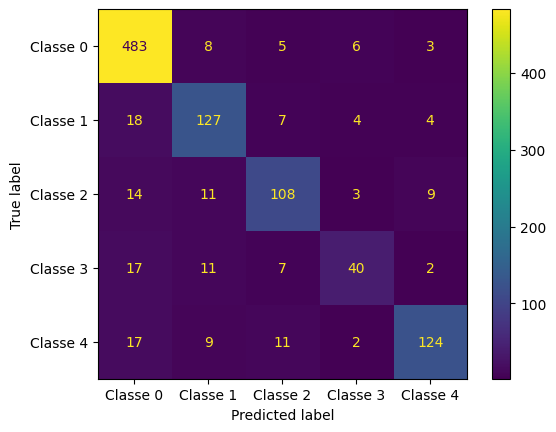

              precision    recall  f1-score   support

    Classe 0       0.88      0.96      0.92       505
    Classe 1       0.77      0.79      0.78       160
    Classe 2       0.78      0.74      0.76       145
    Classe 3       0.73      0.52      0.61        77
    Classe 4       0.87      0.76      0.81       163

    accuracy                           0.84      1050
   macro avg       0.81      0.76      0.78      1050
weighted avg       0.84      0.84      0.84      1050



In [ ]:
# Matriz de confusão
cm = confusion_matrix(y_val, y_pred_val)
labels = ["Classe 0", "Classe 1", "Classe 2", "Classe 3", "Classe 4"]
cmd = ConfusionMatrixDisplay(cm, display_labels=labels)
cmd.plot(values_format='d')
plt.show()
print(classification_report(y_val, y_pred_val, target_names=labels))

In [ ]:
y_pred_val.shape

(1050,)

In [ ]:
from sklearn.neural_network import MLPClassifier

clf = MLPClassifier(hidden_layer_sizes=(200,), max_iter=500, random_state=42, batch_size='auto', learning_rate='constant', solver='adam', activation='relu', alpha=0.0001)
clf.fit(x_train_scaled, y_train)
y_pred = clf.predict(x_test_scaled)

/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:698: UserWarning: Training interrupted by user.
  warnings.warn("Training interrupted by user.")


In [ ]:
x_test_scaled.shape

(4500, 13)

In [ ]:
y_pred.shape

(4500,)

In [ ]:
results = pd.DataFrame({'id': test_data['id'], 'target': y_pred})

# Salvar as previsões em um arquivo CSV
results.to_csv('predições.csv', index=False)

In [ ]:
#Para fins de visualização da tabela
pred_data = pd.read_csv('/content/predições.csv')
display(pred_data)

,id,target
0,2142,0
1,3846,0
2,6177,0
3,11779,0
4,1593,0
...,...,...
4495,11496,0
4496,8856,4
4497,4937,3
4498,7574,4


(1) Software / Biblioteca utilizado: Optei pela utilização da biblioteca Scikit-learn, com a linguagem de programação Python operada por meio da plataforma Google Colab. O Google Colab foi escolhido pela sua integração com Python e pela facilidade de executar código em notebooks.

(2) Passos da resolução da Prova:
1. Primeiramente, fiz a importação de bibliotecas necessárias para a realização da tarefa, como pandas e funções da Scikit-learn (como métricas e os modelos de classificação).
2. Em seguida, fiz o carregamento dos dados de treinamento, e separei os rótulos (y) das entradas (x).
3. Por conseguinte, utilizei a função train_test_split para dividir o conjunto de treinamento em dois conjuntos: um de treino e um de validação, para posteriormente avaliar o modelo.
4. Então, realizei a padronização dos dados com o modelo de pré-processamento StandardScaler.
5. Após o devido tratamento dos dados, testei com o conjunto de treinamento e validação diversos modelos de aprendizado de máquina da Scikit-learn, sendo estes DecisionTreeClassifier, RandomForest, GradientBoosting, SVM, KNN e MLPClassifier. Obtive melhores resultados com a métrica F1 Score com MLPClassifier, KNN e RandomForest.
6. Com o propósito de melhorar meu modelo e encontrar o melhor desempenho, realizei a busca de hiperparâmetros com a técnica GridSearchCV dos 3 modelos que obtive melhores resultados. Avaliei os respetivos modelos com suas melhores combinações de parâmetros e, após o ajuste, obtive o melhor desempenho com o MLPClassifier.
7. Por fim, apliquei o modelo treinado para gerar os rótulos do conjunto de teste. Com essas predições, formulei o arquivo de predições.csv, contendo os rótulos previstos para cada entrada do conjunto de teste.

(3) Explicação da escolha do algoritmo de Aprendizado de Máquina: Após a aplicação de diversos modelos, obtive melhores resultados ao avaliar com a métrica F1 Score utilizando o algoritmo Multi-Layer Perceptron Classifier (MLPClassifier), um algoritmo de aprendizado supervisionado formado por uma rede neural artificial simples, mas eficiente, capaz de modelar relações não lineares complexas nos dados. Essa escolha se deu pois, como uma rede neural de múltiplas camadas, o MLPClassifier consegue aprender representações mais abstratas dos dados.

É válido ressaltar que durante a realização do projeto utilizei, além da documentação da biblioteca Scikit-learn, artigos informativos e GPT-4 apenas para esclarecer dúvidas técnicas, ajudando a aprofundar meu entendimento sobre aspectos específicos do processo de análise.